In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
%cd /content/drive/MyDrive/Doutorado/Disciplinas/4 Trimestre/GA036 - Introdução a ML/data_radar_preprocessing

/content/drive/MyDrive/Doutorado/Disciplinas/4 Trimestre/GA036 - Introdução a ML/data_radar_preprocessing


In [6]:
import tensorflow as tf

import xarray as xr
import numpy as np

import matplotlib.pyplot as plt

In [7]:
filename = "output_data/test_data.nc"

In [8]:
ds = xr.open_dataset(filename)

In [9]:
ds

<xarray.Dataset> Size: 57MB
Dimensions:   (time: 1152, lat: 32, lon: 32, altitude: 6)
Coordinates:
  * time      (time) datetime64[ns] 9kB 2022-11-28 ... 2022-12-30T23:50:00
  * altitude  (altitude) float64 48B 500.0 1e+03 1.5e+03 3e+03 5e+03 7.5e+03
  * lat       (lat) float64 256B -23.14 -23.12 -23.11 ... -22.68 -22.67 -22.65
  * lon       (lon) float64 256B -43.9 -43.87 -43.85 ... -43.1 -43.08 -43.05
Data variables:
    dbzh      (time, lat, lon, altitude) float64 57MB ...

In [10]:
from utils import prepare_data, mse

cfg = {
    "architecture": "ConvLSTM",
    "seq_len": 10,
    "pred_len": 1
}

In [11]:
X = ds["dbzh"].values
X_test, y_test = prepare_data(X, cfg["seq_len"], cfg["pred_len"], cfg=cfg)

In [12]:
model_name = "ConvLSTM_12"
exp_name = "test_run"

In [13]:
# Show model Curve
history = np.load(f"outputs/{model_name}_hist_{exp_name}.npy", allow_pickle=True).item()

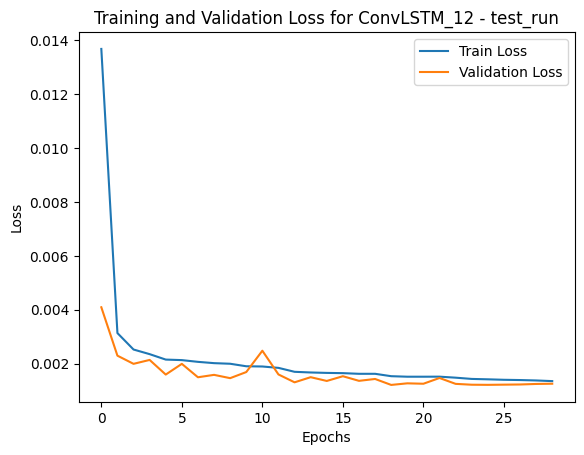

In [14]:
plt.plot(history['loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title(f'Training and Validation Loss for {model_name} - {exp_name}')
plt.show()

In [15]:
# Load model

model_filename = f"outputs/{model_name}_{exp_name}.h5"
model = tf.keras.models.load_model(
	model_filename,
    custom_objects={
		'mse': tf.keras.metrics.mse
	}
)
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm3d_24 (ConvLSTM3D)     │ (None, 10, 6, 32, 32,  │        29,440 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 10, 6, 32, 32,  │            64 │
│ (BatchNormalization)            │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm3d_25 (ConvLSTM3D)     │ (None, 6, 32, 32, 8)   │        20,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 6, 32, 32, 8)   │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_12 (Conv3D)              │ (None, 6, 32, 32, 1)   │           217 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,523 (197.36 KB)

 Trainable params: 50,473 (197.16 KB)

 Non-trainable params: 48 (192.00 B)

 Optimizer params: 2 (12.00 B)

In [16]:
y_pred = model.predict(X_test).reshape(y_test.shape)

36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 264ms/step


In [17]:
import joblib
scaler = joblib.load("scaler.save")

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [18]:
y_test = scaler.inverse_transform(y_test.reshape(-1, 1)).reshape(y_test.shape)
y_pred = scaler.inverse_transform(y_pred.reshape(-1, 1)).reshape(y_pred.shape)

In [19]:
print(mse(y_test, y_pred))
print(np.std(y_test - y_pred))

59.01437225033038
7.667762354182307


In [20]:
y_test = y_test.reshape(-1, X.shape[1], X.shape[2], X.shape[3])
y_pred = y_pred.reshape(-1, X.shape[1], X.shape[2], X.shape[3])

In [21]:
y_test.shape

(1142, 32, 32, 6)

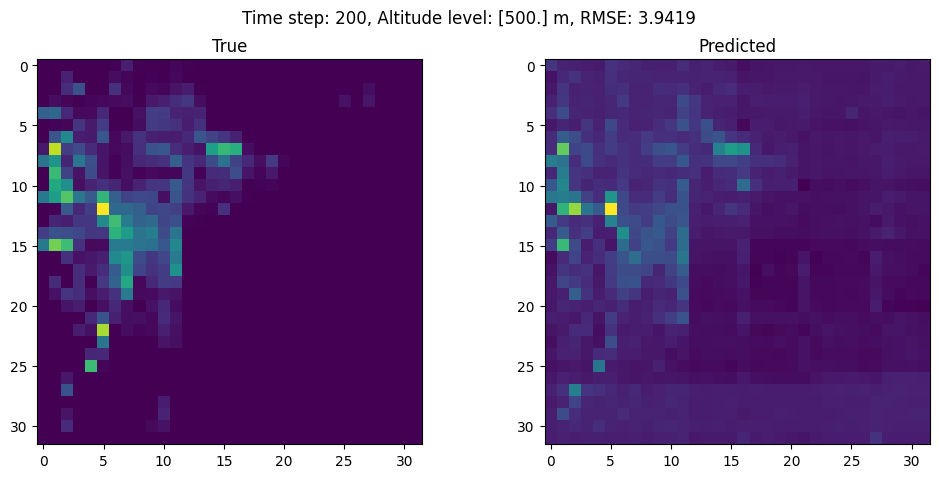

In [22]:
time = 200
alt = 0

sample_true = y_test[time, :, :, alt]
sample_pred = y_pred[time, :, :, alt]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(sample_true)
plt.title('True')

plt.subplot(1, 2, 2)
plt.imshow(sample_pred)
plt.title('Predicted')

plt.suptitle(f'Time step: {time}, Altitude level: {np.unique(ds["altitude"].values[alt])} m, RMSE: {np.sqrt(mse(sample_true, sample_pred)):.4f}')
plt.show()

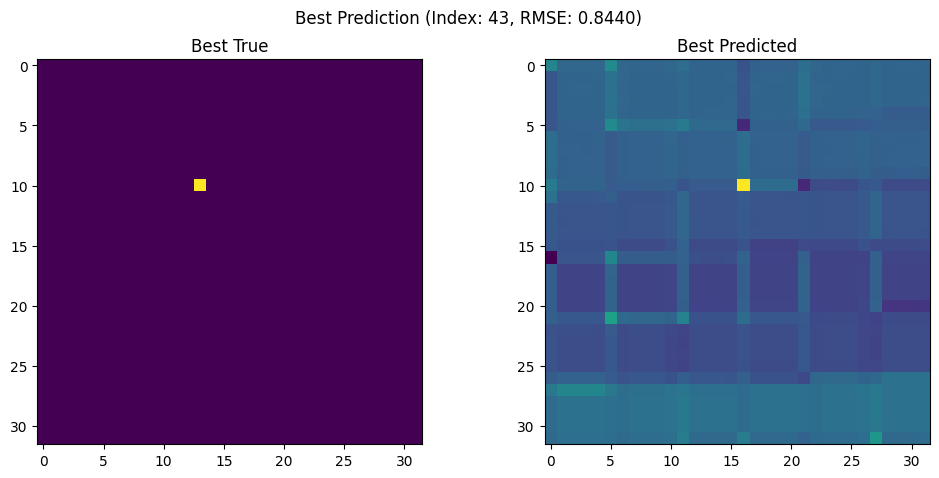

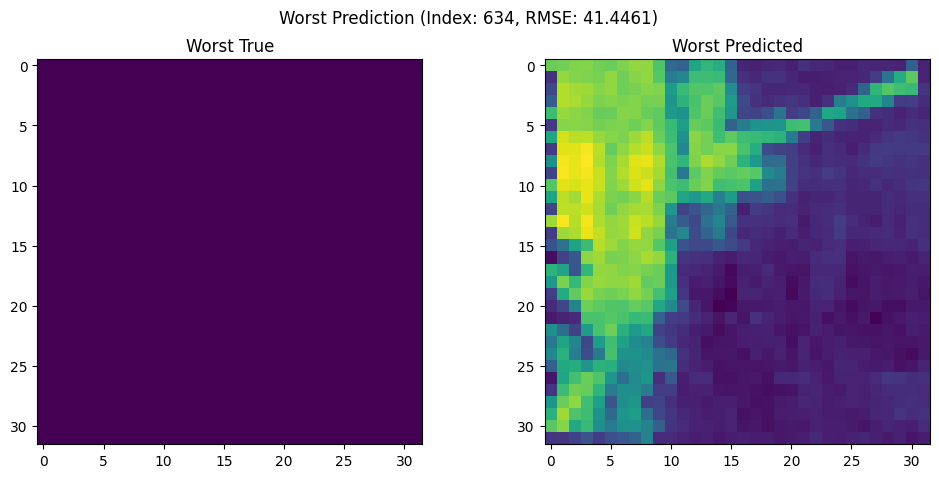

In [23]:
# Find best and worst predictions based on RMSE
rmses = np.sqrt(np.mean((y_test - y_pred) ** 2, axis=(1, 2, 3)))
best_idx = np.argmin(rmses)
worst_idx = np.argmax(rmses)

# Plot best prediction
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(y_test[best_idx, :, :, alt])
plt.title('Best True')
plt.subplot(1, 2, 2)
plt.imshow(y_pred[best_idx, :, :, alt])
plt.title('Best Predicted')
plt.suptitle(f'Best Prediction (Index: {best_idx}, RMSE: {
rmses[best_idx]:.4f})')
plt.show()

# Plot worst prediction
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(y_test[worst_idx, :, :, alt])
plt.title('Worst True')
plt.subplot(1, 2, 2)
plt.imshow(y_pred[worst_idx, :, :, alt])
plt.title('Worst Predicted')
plt.suptitle(f'Worst Prediction (Index: {worst_idx}, RMSE: {rmses[worst_idx]:.4f})')
plt.show()